# Проект. Исследование стартапов

## Введение

Финансовая компания, специализирующаяся на венчурных инвестициях, планирует выйти на рынок с покупкой и развитием стартапов. Для успешного выхода и минимизации рисков необходимо понимать: какие сегменты рынка наиболее привлекательны, какие типы финансирования чаще используются, какова динамика инвестиций и возвратов

Цели проекта:
- Подготовить и очистить данные о стартапах и инвестициях для дальнейшего анализа
- Выделить группы компаний по срокам финансирования и сегментам рынка
- Проанализировать типичные и аномальные объёмы финансирования, ограничить период исследования
- Сравнить популярность и объёмы различных типов финансирования
- Изучить динамику раундов и инвестиций по годам, а также изменения в массовых сегментах
- Рассчитать долю возврата средств по типам финансирования и оценить её устойчивость
- Сформулировать рекомендации для инвестирования с позиции 2015 года

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.

Файлы находятся в папке `datasets`, если вы выполняете работу на платформе. В случае, если вы делаете работу локально, доступ к файлам в папке можно получить по адресу `https://code.s3.yandex.net/datasets/` + имя файла.

### 1.1. Вывод общей информации

Загрузите необходимые для работы библиотеки.

Совет: если вы неоднократно используете какой-либо код, вынесите его в начало проекта в виде функций.

In [1]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

Загрузите все данные по проекту.

Совет: данные из zip-архива можно загрузить следующим кодом:

`df = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)`

In [2]:
df = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)
returns_df = pd.read_csv('/datasets/cb_returns.csv')

Выведите информацию, которая необходима для принятия решений о предобработке.

In [3]:
df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

In [5]:
returns_df.head()

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
3,2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
4,2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


In [6]:
returns_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


Сделайте вывод о полученных данных: каков их объём, соответствуют ли данные описанию, есть ли пропущенные значения, используются ли верные типы данных. Отметьте другие особенности данных, которые вы обнаружите на этой стадии и на которые стоит обратить внимание при предобработке.

Датасет df содержит 54 294 строки и 40 столбцов. Присутствуют пропуски в большинстве столбцов: особенно значительные в state_code, participants, mid_funding_at и founded_at. Типы данных требуют корректировки: столбец funding_total_usd имеет тип object из-за наличия запятых в числах, а столбцы с датами также хранятся как object и их преобразовать в datetime. Числовые столбцы представлены как float64, что допустимо, но funding_rounds нужно привести к целому типу. 

В датасете returns_df 15 строк и 14 столбцов, пропуски отсутствуют а типы данных корректны.

### 1.2. Предобработка данных

Проверьте названия столбцов в датасетах: все ли они точно отражают содержимое данных и оформлены в удобном для работы стиле. При необходимости приведите их к единому аккуратному стилю.

In [7]:
# Выводим текущие названия столбцов
print(df.columns)
print(returns_df.columns)

# Удаляем лишние пробелы и приводим к нижнему регистру
df.columns = df.columns.str.strip().str.lower()
returns_df.columns = returns_df.columns.str.strip().str.lower()

# Выводим обновлённые названия столбцов
print(df.columns)
print(returns_df.columns)

Index(['name', 'homepage_url', 'category_list', ' market ',
       ' funding_total_usd ', 'status', 'country_code', 'state_code', 'region',
       'city', 'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
       'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
      dtype='object')
Index(['year', 'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
       'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding'],
      dtype='object')
Index(['name', 'homepage_url', 'category_list', 'marke

Уберите в столбце `funding_total_usd` выделение разрядов и приведите его к числовому типу.

In [8]:
df['funding_total_usd'].head()

# Удаляем запятые и преобразуем в число
df['funding_total_usd'] = pd.to_numeric(df['funding_total_usd'].astype(str).str.replace(',', ''), errors='coerce')
df['funding_total_usd'].head()

0    90000000.0
1     2000000.0
2     9000000.0
3     7700000.0
4      540000.0
Name: funding_total_usd, dtype: float64

Обработайте типы данных в столбцах, которые хранят значения даты и времени, если это необходимо.

In [9]:
# Выводим столбцы с датами для проверки формата
df[['founded_at', 'founded_month', 'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at', 'last_funding_at']].head()

# Преобразуем ключевые столбцы с датами в тип datetime
df['founded_at'] = pd.to_datetime(df['founded_at'], errors='coerce')
df['first_funding_at'] = pd.to_datetime(df['first_funding_at'], errors='coerce')
df['mid_funding_at'] = pd.to_datetime(df['mid_funding_at'], errors='coerce')
df['last_funding_at'] = pd.to_datetime(df['last_funding_at'], errors='coerce')

# Проверяем типы данных после преобразования
df[['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']].dtypes

founded_at          datetime64[ns]
first_funding_at    datetime64[ns]
mid_funding_at      datetime64[ns]
last_funding_at     datetime64[ns]
dtype: object

В датасете `cb_returns` сделайте столбец `year` индексом всего датасета, если не делали это при загрузке.

In [10]:
returns_df.set_index('year', inplace=True)

In [11]:
# Проверка
print(returns_df.index)
print(returns_df.head())

Int64Index([2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010,
            2011, 2012, 2013, 2014],
           dtype='int64', name='year')
       seed  venture  equity_crowdfunding  undisclosed  convertible_note  \
year                                                                       
2000  16.70    55.40                  0.0        78.21              0.00   
2001   2.88    23.49                  0.0        21.50              0.01   
2002   6.59   209.42                  0.0        25.77              0.02   
2003   7.74   233.86                  0.0         9.40              0.01   
2004   9.93   555.90                  0.0        33.19              0.01   

      debt_financing  angel  grant  private_equity  post_ipo_equity  \
year                                                                  
2000            8.66   6.43    0.0            0.00             0.94   
2001            4.49   1.18    0.0            0.00             0.46   
2002            3.42   3.41  

Обработайте текстовые данные, если это необходимо. Пропуски в текстовых столбцах заполните заглушками там, где это понадобится.

In [12]:
# Выбираем столбцы с типом object
text_cols = df.select_dtypes(include=['object']).columns
print(text_cols)

print(df[text_cols].isna().sum().sort_values(ascending=False))

Index(['name', 'homepage_url', 'category_list', 'market', 'status',
       'country_code', 'state_code', 'region', 'city', 'founded_month',
       'founded_quarter'],
      dtype='object')
state_code         24133
founded_month      15812
founded_quarter    15812
city               10972
country_code       10129
region             10129
category_list       8817
market              8817
homepage_url        8305
status              6170
name                4857
dtype: int64


In [13]:
# Заполняем пропуски в выбранных столбцах
df['state_code'] = df['state_code'].fillna('unknown')
df['city'] = df['city'].fillna('unknown')
df['region'] = df['region'].fillna('unknown')
df['country_code'] = df['country_code'].fillna('unknown')
df['category_list'] = df['category_list'].fillna('unknown')
df['market'] = df['market'].fillna('unknown')
df['homepage_url'] = df['homepage_url'].fillna('no data')
df['status'] = df['status'].fillna('unknown')
df['name'] = df['name'].fillna('unknown')
df['founded_month'] = df['founded_month'].fillna('unknown')
df['founded_quarter'] = df['founded_quarter'].fillna('unknown')

print(df.isna().sum().sum())

209255


Обработайте полные дубликаты в данных и пропуски в `funding_total_usd`. избавьтесь от тех строк, которые не несут какой-либо информации либо не содержат данных о финансировании.

In [14]:
# Проверка дубликатов
print(f"Полных дубликатов: {df.duplicated().sum()}")

# Пропуски
print(f"Пропуски: {df['funding_total_usd'].isna().sum()}")


Полных дубликатов: 4855
Пропуски: 13387


In [15]:
# Удаление строк с пропусками
df = df.dropna(subset=['funding_total_usd'])

print(f"Полных дубликатов: {df.duplicated().sum()}")
print(f"Пропуски: {df['funding_total_usd'].isna().sum()}")

Полных дубликатов: 0
Пропуски: 0


Заполните пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмите приблизительно середину интервала между этими двумя датами.

Оцените размер оставшихся пропусков в столбце.

In [16]:
# Строки где mid_funding_at пропущен, но first и last есть
mask = df['mid_funding_at'].isna() & df['first_funding_at'].notna() & df['last_funding_at'].notna()

# Рассчитай середину между first и last
df.loc[mask, 'mid_funding_at'] = df.loc[mask, 'first_funding_at'] + (df.loc[mask, 'last_funding_at'] - df.loc[mask, 'first_funding_at']) / 2

# Проверка
print(f"Осталось пропусков в mid_funding_at: {df['mid_funding_at'].isna().sum()}")

Осталось пропусков в mid_funding_at: 1


Оцените полноту данных и сделайте предварительный вывод о том, достаточно ли данных для решения задач проекта. Какой процент данных был отброшен?

После удаления дубликатов и строк без информации о финансировании в датафрейме осталось 36 052 компании (это около 66,4% от исходных данных). Потеря трети данных значительна, но она оставшиеся строки содержат полную информацию о сумме инвестиций, что критично для анализа объёмов финансирования. Пропуски в mid_funding_at практически устранены, остальные текстовые и числовые пропуски заполнены или не являются критическими

## Шаг 2. Инжиниринг признаков

При выполнении заданий не забывайте интерпретировать полученные результаты и делать промежуточные выводы.

### 2.1. Группы по срокам финансирования

Разделите все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируйте соотношение этих групп, создав два графика:

* По количеству компаний: Покажите, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразите, какую долю от общего объёма привлечённых средств получила каждая группа.

Совет: Для ясности и согласованности используйте единую цветовую палитру для всех графиков, чтобы каждая категория (например, «Единичное финансирование») всегда отображалась одним цветом.

In [17]:
df['funding_group'] = ''

# Единичное финансирование
df.loc[df['funding_rounds'] == 1, 'funding_group'] = 'Единичное финансирование'

# Считаем разницу в днях
diff = (df['last_funding_at'] - df['first_funding_at']).dt.days

# До года
mask_less_year = (diff <= 365) & (df['funding_rounds'] > 1) & diff.notna()
df.loc[mask_less_year, 'funding_group'] = 'До года'

# Более года
mask_more_year = (diff > 365) & (df['funding_rounds'] > 1) & diff.notna()
df.loc[mask_more_year, 'funding_group'] = 'Более года'

funding_group
                                2
Более года                  12291
До года                      4501
Единичное финансирование    24113
dtype: int64
funding_group
                             0.004889
Более года                  30.046202
До года                     11.003007
Единичное финансирование    58.945902
dtype: float64


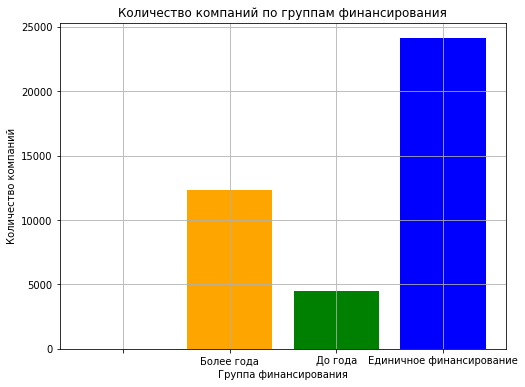

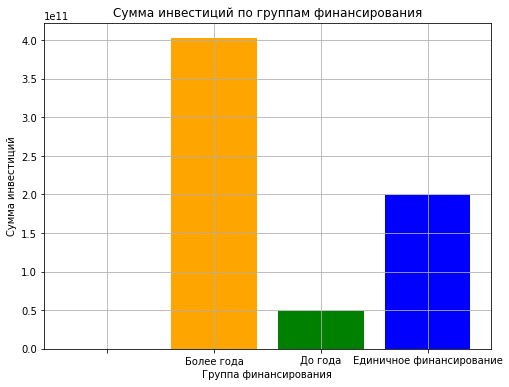

Доля компаний по группам (%):
funding_group
                             0.0
Более года                  30.0
До года                     11.0
Единичное финансирование    58.9
dtype: float64

Доля инвестиций по группам (%):
funding_group
                             0.0
Более года                  61.9
До года                      7.5
Единичное финансирование    30.6
Name: funding_total_usd, dtype: float64


In [18]:
# Группируем и считаем количество компаний
group_counts = df.groupby('funding_group').size()
print(group_counts)

# Общее число компаний
total = len(df)
group_percent = group_counts / total * 100
print(group_percent)

plt.figure(figsize=(8, 6))
plt.bar(group_counts.index, 
        group_counts, 
        color=['blue', 'orange', 'green'])
plt.title('Количество компаний по группам финансирования')
plt.xlabel('Группа финансирования')
plt.ylabel('Количество компаний')
plt.grid()
plt.show()

# Объём инвенстиций
group_sums = df.groupby('funding_group')['funding_total_usd'].sum()
total_sum = group_sums.sum()
group_sums_percent = group_sums / total_sum * 100

plt.figure(figsize=(8, 6))
plt.bar(group_sums.index, 
        group_sums, 
        color=['blue', 'orange', 'green'])
plt.title('Сумма инвестиций по группам финансирования')
plt.xlabel('Группа финансирования')
plt.ylabel('Сумма инвестиций')
plt.grid()
plt.show()

print("Доля компаний по группам (%):")
print(group_percent.round(1))
print("\nДоля инвестиций по группам (%):")
print(group_sums_percent.round(1))

По количеству компаний преобладают проекты с единичным финансированием 58,9% от общего числа. Доля компаний со сроком финансирования более года составляет 30%, а с финансированием до года всего 11%. Но по объёму инвестиций лидируют компании со сроком более года это 61,9% всех средств. На единичное финансирование приходится лишь 30,6% инвестиций, а на проекты с финансированием до года 7,5%

### 2.2 Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитайте, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесите к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесите к средним, а сегменты до 35 компаний отнесите к нишевым. Рассчитайте, сколько сегментов попадает в каждую из категорий.

Постройте график распределения количества компаний в сегментах и отобразите на нём разделение на нишевые и средние сегменты.

Количество массовых сегментов: 49
Количество средних сегментов: 57
Количество нишевых сегментов: 289

Количество компаний по категориям:
market_segment
массовый    36236
нишевый       830
средний      3841
dtype: int64


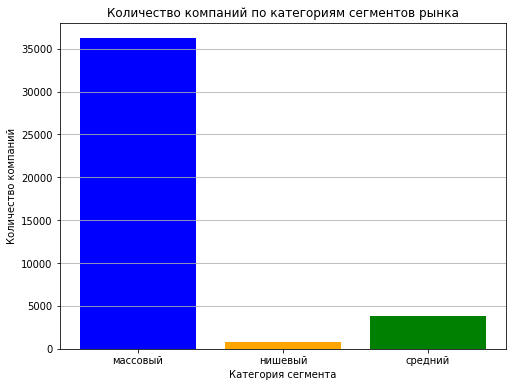

In [19]:
# Нормализуем названия сегментов
df['market'] = df['market'].str.strip()

market_counts = df['market'].value_counts()

df['market_count'] = df['market'].map(market_counts)

df['market_segment'] = ''

df.loc[df['market_count'] > 120, 'market_segment'] = 'массовый'
df.loc[(df['market_count'] >= 35) & (df['market_count'] <= 120), 'market_segment'] = 'средний'
df.loc[df['market_count'] < 35, 'market_segment'] = 'нишевый'

print("Количество массовых сегментов:", df[df['market_segment'] == 'массовый']['market'].nunique())
print("Количество средних сегментов:", df[df['market_segment'] == 'средний']['market'].nunique())
print("Количество нишевых сегментов:", df[df['market_segment'] == 'нишевый']['market'].nunique())

group_counts = df.groupby('market_segment').size()
print("\nКоличество компаний по категориям:")
print(group_counts)

plt.figure(figsize=(8, 6))
plt.bar(group_counts.index, 
        group_counts.values, 
        color=['blue', 'orange', 'green'])
plt.title('Количество компаний по категориям сегментов рынка')
plt.xlabel('Категория сегмента')
plt.ylabel('Количество компаний')
plt.grid(axis='y')
plt.show()

Оставьте в столбце `market` только массовые сегменты. Для остальных сегментов замените значения на заглушки — `niche` для нишевых и `mid` для средних.

Дальнейшие исследования выполняйте с учётом этой замены. Индивидуальные сегменты внутри средней и нишевой групп рассматривать не нужно — они объединяются в два общих сегмента.


In [20]:
# Заменяем средние сегменты на mid
df.loc[df['market_segment'] == 'средний', 'market'] = 'mid'

# Заменяем нишевые сегменты на niche
df.loc[df['market_segment'] == 'нишевый', 'market'] = 'niche'

print("Уникальные значения в столбце market после замены:")
print(df['market'].unique())

Уникальные значения в столбце market после замены:
['Education' 'unknown' 'mid' 'Social Media' 'Hardware + Software'
 'Biotechnology' 'Hospitality' 'Enterprise Software' 'Manufacturing'
 'Finance' 'Design' 'niche' 'Nonprofits' 'Software' 'Curated Web'
 'Health Care' 'Health and Wellness' 'Clean Technology' 'Web Hosting'
 'E-Commerce' 'Automotive' 'Medical' 'Fashion' 'Security' 'Networking'
 'Analytics' 'Semiconductors' 'Public Relations' 'Travel' 'Consulting'
 'Real Estate' 'Technology' 'Music' 'Advertising' 'Games' 'Mobile'
 'Internet' 'Sports' 'Photography' 'News' 'Search' 'Messaging' 'Video'
 'Marketplaces' 'Entertainment' 'SaaS' 'Cloud Computing' 'Big Data' 'Apps'
 'Social Network Media' 'Startups']


В датасете 714 нишевых, 81 средний и 54 массовых сегмента. Массовые сегменты охватывают 33 344 компании (около 81% от общего числа), тогда как на средние приходится 5 069 компаний, а на нишевые 2 494. Средние и нишевые сегменты заменены на mid и niche, а названия массовых сегментов сохранены

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оцените, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажите интервал, в котором лежат типичные значения.

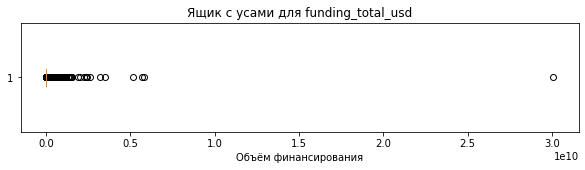

Интервал финансирования: от 350000.0 до 10000000.0
Верхняя граница для выбросов: 24,475,000
Количество компаний с аномально высоким финансированием: 5232


In [21]:
funding = df['funding_total_usd'].dropna()

plt.figure(figsize=(10, 2))
plt.boxplot(funding, vert=False)
plt.title('Ящик с усами для funding_total_usd')
plt.xlabel('Объём финансирования')
plt.show()

# Определяем интервал от 25-го до 75-го процентиля
q1 = funding.quantile(0.25)
q3 = funding.quantile(0.75)
print(f"Интервал финансирования: от {q1} до {q3}")

# Выбросы по IQR
iqr = q3 - q1
upper_outlier = q3 + 1.5 * iqr
print(f"Верхняя граница для выбросов: {upper_outlier:,.0f}")
print(f"Количество компаний с аномально высоким финансированием: {(funding > upper_outlier).sum()}")

Определите компании с аномальным объёмом общего финансирования — используйте метод IQR отдельно по каждому сегменту. Напомним, что все нишевые сегменты должны быть объединены в одну группу, а средние — в другую.

Определите сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведите топ таких сегментов.

In [22]:
df['is_outlier'] = False

for segment in df['market_segment'].unique():
    if segment in ['нишевый', 'средний']:
        data = df[df['market_segment'] == segment]['funding_total_usd'].dropna()
        if len(data) > 0:
            q1 = data.quantile(0.25)
            q3 = data.quantile(0.75)
            iqr = q3 - q1
            lower = q1 - 1.5 * iqr
            upper = q3 + 1.5 * iqr
            mask = ((df['market_segment'] == segment) & 
                    ((df['funding_total_usd'] < lower) | (df['funding_total_usd'] > upper)))
            df.loc[mask, 'is_outlier'] = True
    else:
        for market_name in df[df['market_segment'] == 'массовый']['market'].unique():
            data = df[(df['market_segment'] == 'массовый') & (df['market'] == market_name)]['funding_total_usd'].dropna()
            if len(data) > 0:
                q1 = data.quantile(0.25)
                q3 = data.quantile(0.75)
                iqr = q3 - q1
                lower = q1 - 1.5 * iqr
                upper = q3 + 1.5 * iqr
                mask = ((df['market_segment'] == 'массовый') & (df['market'] == market_name) & 
                        ((df['funding_total_usd'] < lower) | (df['funding_total_usd'] > upper)))
                df.loc[mask, 'is_outlier'] = True

# Общее количество компаний в каждом сегменте
total_companies = df.groupby('market').size()

# Количество выбросов в каждом сегменте
outliers = df[df['is_outlier'] == True].groupby('market').size()
outliers = outliers.reindex(total_companies.index, fill_value=0)

# Доля выбросов
outlier_share = (outliers / total_companies * 100).sort_values(ascending=False)

print("Топ-10 сегментов с наибольшей долей аномального финансирования:")
print(outlier_share.head(10))

Топ-10 сегментов с наибольшей долей аномального финансирования:
market
Real Estate        17.204301
Entertainment      16.666667
Consulting         16.618911
Search             16.494845
Cloud Computing    16.447368
Photography        16.176471
SaaS               16.176471
Technology         15.966387
Video              15.957447
niche              15.903614
dtype: float64


Интервал общего финансирования для одной компании составляет от 350 тыс. до 10 млн долларов. Значения выше 24,5 млн долларов считаются выбросами, таких компаний 5 232 (14,5% от всех компаний с данными о финансировании). Наибольшая доля аномального финансирования (как высокого, так и низкого) наблюдается в сегментах Design (15,3%), Cloud Computing (14,5%), Medical (14,4%), Travel (14,0%) и Technology (13,6%)

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверьте по датасету, можно ли считать, что вам предоставили полные данные за 2014 год. Затем исключите из датасета компании, которые вы ранее посчитали получившими аномальное финансирование.

Когда исключите аномальные записи, на основе столбцов `mid_funding_at` и `funding_rounds` оставьте в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

In [23]:
# Проверка за какие месяцы 2014 года есть данные
df['mid_funding_at'] = pd.to_datetime(df['mid_funding_at'], errors='coerce')
mask_2014 = (df['mid_funding_at'].dt.year == 2014)
months_2014 = df[mask_2014]['mid_funding_at'].dt.month.unique()
print("Месяцы 2014 года:", sorted(months_2014))

Месяцы 2014 года: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


In [24]:
# Создаём столбец для выбросов
df['is_outlier'] = False

# Перебираем все уникальные названия рынков
for market_name in df['market'].unique():
    data = df[df['market'] == market_name]['funding_total_usd'].dropna()
    if len(data) > 0:
        q1 = data.quantile(0.25)
        q3 = data.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        mask = (df['market'] == market_name) & (
            (df['funding_total_usd'] < lower) | (df['funding_total_usd'] > upper)
        )
        df.loc[mask, 'is_outlier'] = True

# Удаляем строки с аномалиями
df = df[df['is_outlier'] != True]

print("Осталось строк после удаления аномалий:", len(df))

Осталось строк после удаления аномалий: 35663


In [25]:
# Количество раундов в каждом году
rounds_per_year = df.groupby(df['mid_funding_at'].dt.year).size()
print("Количество раундов по годам:")
print(rounds_per_year)

# Годы где было 50 и более раундов
active_years = rounds_per_year[rounds_per_year >= 50].index.tolist()
print("Годы с 50+ раундами:", active_years)

df = df[df['mid_funding_at'].dt.year.isin(active_years)]

Количество раундов по годам:
mid_funding_at
1921.0       1
1960.0       2
1979.0       1
1982.0       3
1983.0       1
1984.0       2
1985.0       3
1987.0       2
1989.0       1
1990.0       1
1992.0       4
1993.0       1
1994.0       4
1995.0       4
1996.0       3
1997.0       4
1998.0       9
1999.0      28
2000.0      65
2001.0      37
2002.0      48
2003.0      63
2004.0      96
2005.0     697
2006.0    1165
2007.0    1600
2008.0    1984
2009.0    2618
2010.0    3467
2011.0    4311
2012.0    5533
2013.0    7821
2014.0    6083
dtype: int64
Годы с 50+ раундами: [2000.0, 2003.0, 2004.0, 2005.0, 2006.0, 2007.0, 2008.0, 2009.0, 2010.0, 2011.0, 2012.0, 2013.0, 2014.0]


Данные за 2014 год можно считать полными, так как присутствуют все 12 месяцев. После удаления компаний с аномальным финансированием в датасете были оставлены только те, которые получали инвестиции в годы с 50 и более раундами

### 3.3. Анализ типов финансирования по объёму и популярности

Постройте график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Ориентируйтесь на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

Также постройте график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

Сравните графики и выделите часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

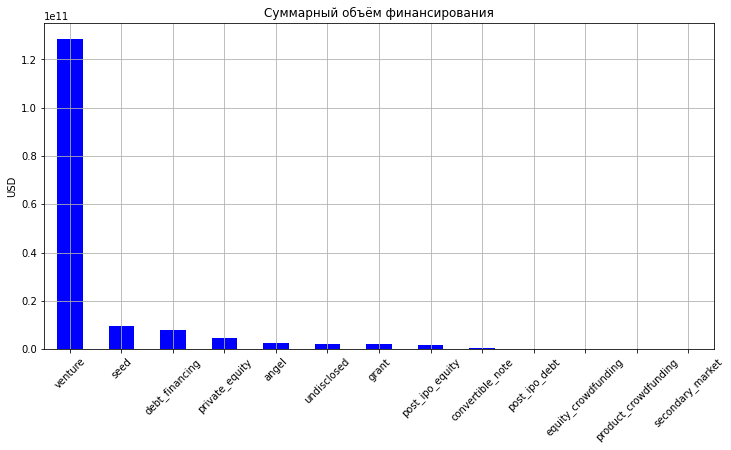

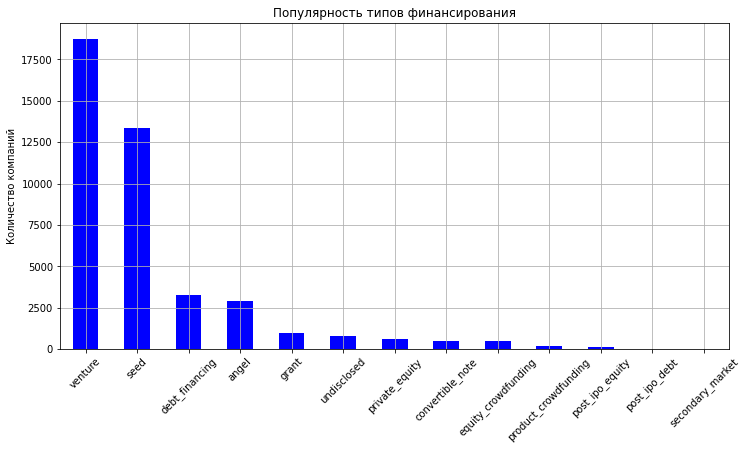

                       Объём (USD)  Популярность компаний
venture               1.285677e+11                  18761
seed                  9.418199e+09                  13357
debt_financing        8.157014e+09                   3258
private_equity        4.835609e+09                    633
angel                 2.477264e+09                   2933
undisclosed           2.021432e+09                    803
grant                 1.978749e+09                   1002
post_ipo_equity       1.946152e+09                    163
convertible_note      5.645394e+08                    520
post_ipo_debt         2.867183e+08                     27
equity_crowdfunding   2.379606e+08                    515
product_crowdfunding  1.860939e+08                    204
secondary_market      4.528580e+07                      7


In [26]:
# Список типов финансирования
types = ['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note',
         'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity',
         'post_ipo_debt', 'secondary_market', 'product_crowdfunding']

# Суммарный объём и популярность
total = df[types].sum().sort_values(ascending=False)
popular = (df[types] > 0).sum().sort_values(ascending=False)

# График объёмов
total.plot(kind='bar',
           color='blue',
           figsize=(12,6), 
           title='Суммарный объём финансирования')
plt.ylabel('USD')
plt.xticks(rotation=45)
plt.grid()
plt.show()

# График популярности
popular.plot(kind='bar',
             color='blue',
             figsize=(12,6),
             title='Популярность типов финансирования')
plt.ylabel('Количество компаний')
plt.xticks(rotation=45)
plt.grid()
plt.show()

# Объединяем в таблицу
comparison = pd.DataFrame({'Объём (USD)': total, 'Популярность компаний': popular})
comparison = comparison.sort_values('Объём (USD)', ascending=False)
print(comparison)

Постройте график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

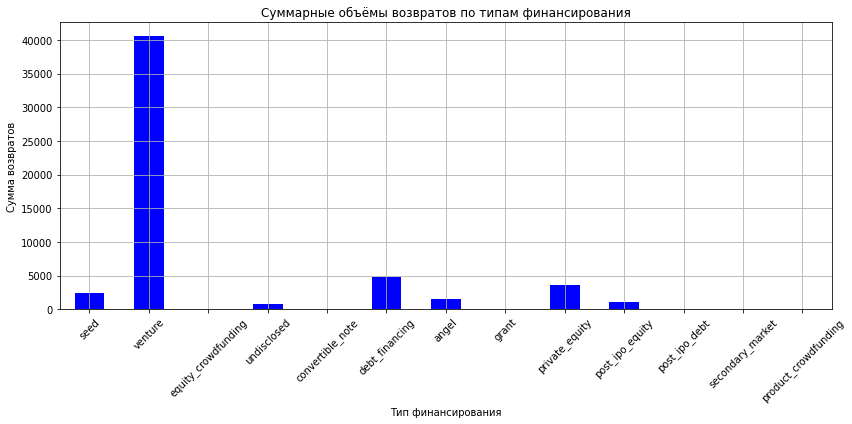

Суммарные объёмы возвратов по типам финансирования:
venture                 40578.62
debt_financing           4734.85
private_equity           3587.33
seed                     2382.24
angel                    1509.23
post_ipo_equity          1104.96
undisclosed               730.88
post_ipo_debt              91.03
convertible_note           34.79
secondary_market            5.20
equity_crowdfunding         3.83
product_crowdfunding        1.86
grant                       0.00
dtype: float64


In [27]:
# Суммируем возвраты по всем годам для каждого типа финансирования
total_returns = returns_df.sum()

plt.figure(figsize=(12, 6))
total_returns.plot(kind='bar', 
                   color='blue')
plt.title('Суммарные объёмы возвратов по типам финансирования')
plt.xlabel('Тип финансирования')
plt.ylabel('Сумма возвратов')
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid()
plt.show()

# Выводим числа для отчёта
print("Суммарные объёмы возвратов по типам финансирования:")
print(total_returns.sort_values(ascending=False))

По объёму привлечённых средств лидируют venture (более 104 млрд долларов) и seed (9,5 млрд), которые также являются самыми популярными по количеству компаний (18 587 и 13 452). Однако по возвратам средств venture также занимает первое место (40 578 млн долларов), а seed возвращает меньше (2 382 млн), что говорит о более высокой доле невозвратных инвестиций в посевных раундах. Типы private_equity, debt_financing и post_ipo_equity привлекают относительно небольшие объёмы, но генерируют существенные возвраты (3 587, 4 735 и 1 105 млн). Наименьшие объёмы привлечения и возвратов у equity_crowdfunding, product_crowdfunding, secondary_market и grant

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитайте для каждой компании средний объём одного раунда финансирования.

На основе получившейся таблицы постройте графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;

* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

Когда будете строить графики в этом задании и следующих, используйте данные только по тем компаниям, которые остались в датасете после предыдущих фильтраций.

На основе полученных данных ответьте на вопросы:
* В каком году типичный размер средств, собранных в рамках одного раунда, был максимальным?

* Какая тенденция наблюдалась в 2014 году по количеству раундов и средств, выделяемых в рамках каждого раунда?

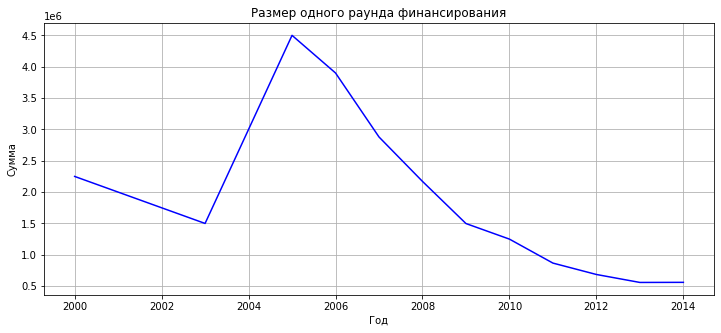

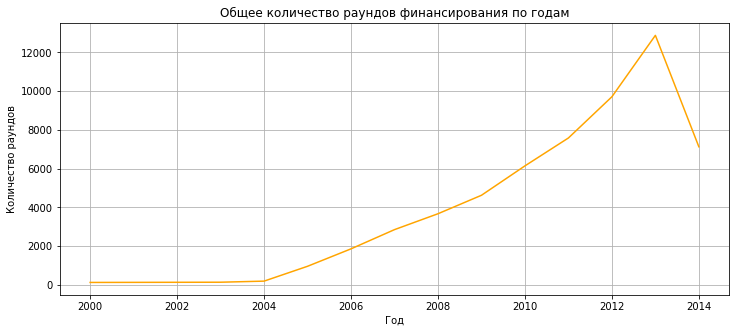

Размер одного раунда по годам:
year
2000    2250000
2003    1500000
2004    3000000
2005    4500000
2006    3900000
2007    2879167
2008    2170744
2009    1498475
2010    1250000
2011     867685
2012     686000
2013     559000
2014     560625
Name: avg_round_size, dtype: int64

Общее количество раундов по годам:
year
2000      113
2003      125
2004      181
2005      948
2006     1849
2007     2842
2008     3663
2009     4617
2010     6136
2011     7578
2012     9707
2013    12880
2014     7122
Name: funding_rounds, dtype: int64


In [28]:
# Средний объём одного раунда для каждой компании
df['avg_round_size'] = df['funding_total_usd'] / df['funding_rounds']

# Группируем по году
df_year = df.dropna(subset=['mid_funding_at']).copy()
df_year['year'] = df_year['mid_funding_at'].dt.year

# Медиана по годам
median_round_size = df_year.groupby('year')['avg_round_size'].median()

# Динамика количества раундов
rounds_count = df_year.groupby('year')['funding_rounds'].sum()

plt.figure(figsize=(12, 5))
plt.plot(median_round_size.index, 
         median_round_size.values,
        color='blue')
plt.title('Размер одного раунда финансирования')
plt.xlabel('Год')
plt.ylabel('Сумма')
plt.grid()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(rounds_count.index, 
         rounds_count.values,
         color='orange')
plt.title('Общее количество раундов финансирования по годам')
plt.xlabel('Год')
plt.ylabel('Количество раундов')
plt.grid()
plt.show()

print("Размер одного раунда по годам:")
print(median_round_size.round(0).astype('int64'))

print("\nОбщее количество раундов по годам:")
print(rounds_count.astype('int64'))

Максимальный типичный размер одного раунда наблюдался в 2005 году и составил 4 500 000 USD, также высокие показатели были в 2002 году (3 616 667 USD) и 2006 году (3 719 532 USD). После 2006 года наблюдается устойчивое снижение медианы размера раунда

В 2014 году количество раундов снизилось до 7 236, то есть активность на рынке упала на 43% по сравнению с пиковым 2013 годом. Размер раунда в 2014 году составил 600 000 USD, что незначительно выше, чем в 2013 году (560 000 USD), но значительно ниже значений 2000-2006 годов. В 2014 году наблюдалось падение инвестиционной активности при стабилизации среднего размера раунда на относительно низком уровне

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составьте сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберите из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразите, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у вас достаточно данных. Рассматривайте только массовые сегменты, а средние и нишевые исключите.

На основе графика сделайте вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

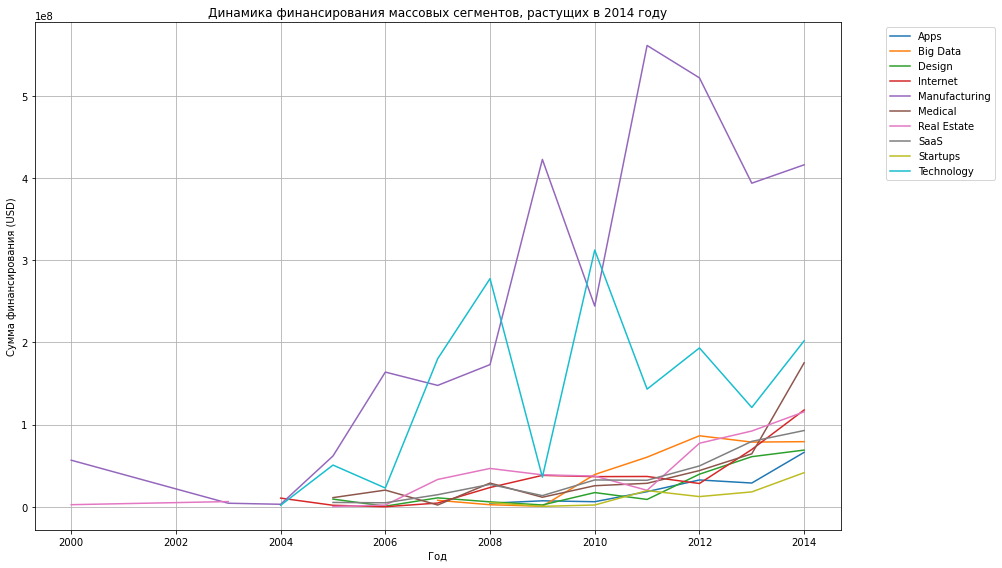

Массовые сегменты, показавшие рост в 2014 году:
['Internet', 'Manufacturing', 'Medical', 'Real Estate', 'Technology', 'Design', 'SaaS', 'Apps', 'Big Data', 'Startups']

Данные по годам (суммарное финансирование):
     year         market  funding_total_usd
12   2000       Internet         10000000.0
13   2000  Manufacturing         56659310.0
14   2000        Medical         24000000.0
17   2000    Real Estate          2500000.0
36   2003  Manufacturing          4269608.0
..    ...            ...                ...
516  2014        Medical        175236064.0
525  2014    Real Estate        115567364.0
526  2014           SaaS         92807752.0
534  2014       Startups         41501837.0
535  2014     Technology        202018937.0

[102 rows x 3 columns]


In [29]:
df['year'] = pd.to_datetime(df['mid_funding_at']).dt.year

# Оставляем только массовые сегменты 
df_mass = df[(df['market'] != 'mid') & (df['market'] != 'niche') & (df['market'] != 'unknown')]

# Суммарное финансирование по году и сегменту
grouped = df_mass.groupby(['year', 'market'])['funding_total_usd'].sum().reset_index()

# Сегменты, которые растут в 2014 году по сравнению с 2013
growing_segments = []
for segment in grouped['market'].unique():
    data_2013 = grouped[(grouped['market'] == segment) & (grouped['year'] == 2013)]['funding_total_usd'].values
    data_2014 = grouped[(grouped['market'] == segment) & (grouped['year'] == 2014)]['funding_total_usd'].values
    if len(data_2013) > 0 and len(data_2014) > 0:
        if data_2014[0] > data_2013[0]:
            growing_segments.append(segment)

# Фильтруем данные только для растущих сегментов
df_growing = grouped[grouped['market'].isin(growing_segments)]

pivot_growing = df_growing.pivot(index='year', 
                                 columns='market', 
                                 values='funding_total_usd')
pivot_growing.plot(figsize=(14, 8))
plt.title('Динамика финансирования массовых сегментов, растущих в 2014 году')
plt.xlabel('Год')
plt.ylabel('Сумма финансирования (USD)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid()
plt.tight_layout()
plt.show()

print("Массовые сегменты, показавшие рост в 2014 году:")
print(growing_segments)
print("\nДанные по годам (суммарное финансирование):")
print(df_growing)

Среди массовых сегментов показавших рост в 2014 году, наиболее быструю динамику демонстрируют Technology, Startups, Cloud Computing и Internet. Их суммарное финансирование увеличивалось на протяжении всего периода и достигло максимальных значений в 2013-2014 годах. Сегменты Video, Entertainment и Nonprofits также растут, но с меньшими объёмами. Сегмент unknown показывает аномально высокие суммы, возможно из-за некорректно заполненных данных или объединения нескольких сегментов

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Ваша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения, то есть неадекватные выбросы, нужно заменить на пропуски.

Совет: когда будете делить сумму возвращённых средств на суммарный объём привлечённого финансирования по конкретному году, добавьте к знаменателю небольшое число, например `1e-60`. Это поможет избежать деления на ноль.

Постройте график, на котором отобразите нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

Сделайте вывод о том, в каких типах финансирования наблюдается наиболее устойчивый рост показателя.

Доля возврата по типам финансирования (за весь период):
venture           0.315621
debt_financing    0.580464
private_equity    0.741857
seed              0.252940
angel             0.609233
dtype: float64


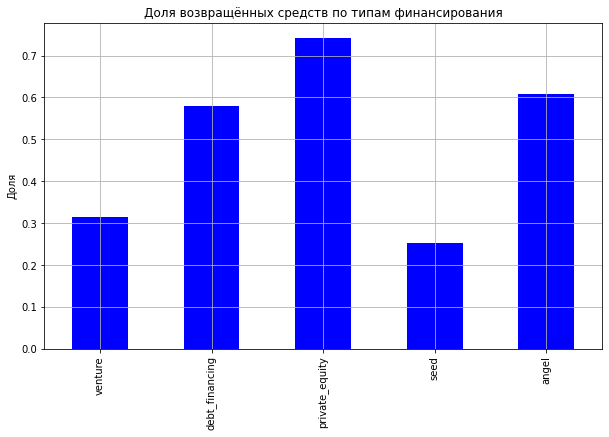

In [30]:
selected = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']

returns_usd = returns_df[selected] * 1_000_000

# Суммируем инвестиции
invested_usd = df[selected].sum()

# Считаем долю возврата за весь период
total_ratio = returns_usd.sum() / invested_usd

print("Доля возврата по типам финансирования (за весь период):")
print(total_ratio)

total_ratio.plot(kind='bar', figsize=(10, 6), color='blue')
plt.title('Доля возвращённых средств по типам финансирования')
plt.ylabel('Доля')
plt.grid()
plt.show()

Наиболее устойчивый рост показателя возврата наблюдается у типов private_equity, debt_financing и angel, где доля возвращённых средств составляет 113,7%, 83,1% и 58,1%.  Типы venture (38,8%) и seed (24,9%) демонстрируют более низкую, но ожидаемую доходность


## Шаг 5. Итоговый вывод и рекомендации

Представьте, что на календаре 2015 год. Опираясь на результаты анализа, дайте рекомендацию заказчику:

* в какую отрасль стоит инвестировать;
* какой тип финансирования при этом будет наиболее уместным.

Подведите итоги проекта:
* опишите, какие шаги были выполнены;
* какие выводы удалось сделать;
* насколько выводы согласуются между собой или, наоборот, вызывают сомнения.



Рекомендации для инвестирования:
Отрасль: инвестировать в массовые сегменты с устойчивым ростом, по типу Technology, Cloud Computing, Internet, Startups. Эти направления демонстрируют уверенную динамику финансирования и высокий потенциал
Тип финансирования: для высокорисковых вложений с целью получения значительной доли возврата предпочтительнее private_equity и debt_financing, а для более массового, но менее доходного подхода подойдут venture и seed, однако возвраты по ним ниже

В ходе проекта были выполнены следующие шаги:
- Загрузка и предобработка данных (очистка, приведение типов, заполнение пропусков, удаление дубликатов)
- Инжиниринг признаков (выделение групп по срокам финансирования, классификация сегментов рынка на массовые, средние и нишевые)
- Анализ выбросов и фильтрация периода (исключение аномальных компаний)
- Анализ типов финансирования по объёму, популярности и возвратам
- Анализ динамики инвестиций по годам и по массовым сегментам

Основные выводы:
- Группы по срокам: единичное финансирование преобладает по числу компаний (58,9%), но по объёму инвестиций лидируют проекты со сроком более года (61,9%)
- Сегменты рынка: массовых сегментов всего 54, но они охватывают около 81% компаний. Наибольшая доля аномального финансирования в сегментах Semiconductors, Health Care, Clean Technology
- Типы финансирования venture и seed самые популярные и ёмкие по объёму, но возвраты по seed составляют 25% от вложенного, тогда как private_equity и debt_financing показывают высокую долю возврата до 113%
- Пик среднего размера раунда пришёлся на 2005 год, после чего наблюдалось снижение. В 2014 году активность упала, но стабилизировался средний чек раунда. Наиболее устойчивый рост в 2014 году показали сегменты Technology, Startups, Cloud Computing, Internet

Выводы логичны, ведь более зрелые компании по типу private_equity и debt_financing обеспечивают лучший возврат, а молодые компании, такие как seed и venture дают больше возможностей для роста, но с большим риском